# Trabalho 2: Planeamento de Trajetos (experiências)

Inteligência Artificial (UC 90498), ESTGA. Cristiano Saraiva (125242), Nicolas Uchimura (122888).

Este notebook corre todas as experiências do trabalho e mostra os resultados.
Os algoritmos estão no módulo `pathfinding/` e as funções de medição e de figuras em `experiencias.py`.
O notebook só as chama e mostra os resultados, por isso os números coincidem com os de `resultados/`.

**Índice**

1. Cenários
2. Validação com o Anexo A
3. Dijkstra vs. A*
4. Heurísticas e modelos de movimento (incluindo a heurística não admissível)
5. Visualização dos caminhos e dos nós explorados
6. Escalabilidade
7. Extensão: Weighted A*
8. Terrenos: caminho mais curto vs. caminho mais barato

In [24]:
import math
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

import experiencias as ex
from pathfinding import astar, dijkstra, ler_mapa, pesquisar
from planear import desenhar

REP = 10  # repetições por medição de tempo
ex.RESULTADOS.mkdir(exist_ok=True)
ex.FIGURAS.mkdir(exist_ok=True)
ex.estilo(plt)


def secao(md_completo: str, titulo: str) -> str:
    """Extrai uma secção ('## titulo...') do Markdown gerado por ex.tabelas()."""
    partes = md_completo.split("\n## ")
    for p in partes:
        if p.startswith(titulo):
            return "### " + p
    raise KeyError(titulo)

## 1. Cenários

Usamos nove cenários: os três do Anexo A e seis criados pelo grupo com `gerar_cenarios.py`.
Os geradores usam a semente base 42, e os mapas gerados estão guardados em `cenarios/`.

In [25]:
grelhas = [ler_mapa(p) for p in sorted(ex.CENARIOS.glob("*.txt"))]
linhas = ["| Cenário | Dimensão | S | G | Custos | Obstáculos |", "|---|---|---|---|---|---|"]
for g in grelhas:
    livres = [c for f in g.custos for c in f if c is not None]
    obst = g.linhas * g.colunas - len(livres)
    linhas.append(f"| {g.nome} | {g.linhas}×{g.colunas} | {g.inicio} | {g.objetivo} "
                  f"| {min(livres)}–{max(livres)} | {100 * obst / (g.linhas * g.colunas):.0f}% |")
display(Markdown("\n".join(linhas)))

| Cenário | Dimensão | S | G | Custos | Obstáculos |
|---|---|---|---|---|---|
| A_labirinto_7x10 | 7×10 | (0, 0) | (4, 9) | 1–1 | 37% |
| B_terrenos_5x9 | 5×9 | (0, 0) | (4, 8) | 1–9 | 27% |
| C_sem_caminho_4x6 | 4×6 | (0, 0) | (3, 5) | 1–1 | 25% |
| D_labirinto_61x61 | 61×61 | (1, 1) | (59, 59) | 1–1 | 49% |
| E_aberto_120x120 | 120×120 | (15, 12) | (104, 107) | 1–1 | 5% |
| F_terrenos_40x40 | 40×40 | (20, 1) | (20, 38) | 1–9 | 3% |
| G_obstaculo_U_60x60 | 60×60 | (30, 8) | (30, 51) | 1–1 | 2% |
| H_aleatorio_80x80 | 80×80 | (0, 0) | (79, 79) | 1–9 | 28% |
| I_sem_caminho_100x100 | 100×100 | (10, 10) | (75, 80) | 1–1 | 10% |

## 2. Validação com o Anexo A

Os custos esperados são A: 17 / 17, B: 20 / 18,83 e C: sem caminho, em 4 / 8 direções.
Os nós expandidos de referência são cerca de 35/27 (A), 31/29 (B) e 6/6 (C); são indicativos, porque dependem do desempate.

In [26]:
for nome in ex.ANEXO_A:
    g = ler_mapa(ex.CENARIOS / f"{nome}.txt")
    print(f"== {nome}")
    for m in (4, 8):
        d, a = dijkstra(g, m), astar(g, m, ex.H_REF[m])
        custo = f"{d.custo:.2f}" if d.encontrou else "sem caminho"
        print(f"  {m} dir.: custo {custo:>11} | Dijkstra {d.expandidos:3d} nós | "
              f"A* ({ex.H_REF[m]}) {a.expandidos:3d} nós | mesmo custo: {d.custo == a.custo}")

== A_labirinto_7x10
  4 dir.: custo       17.00 | Dijkstra  35 nós | A* (manhattan)  27 nós | mesmo custo: True
  8 dir.: custo       17.00 | Dijkstra  35 nós | A* (octile)  27 nós | mesmo custo: True
== B_terrenos_5x9
  4 dir.: custo       20.00 | Dijkstra  30 nós | A* (manhattan)  29 nós | mesmo custo: True
  8 dir.: custo       18.83 | Dijkstra  30 nós | A* (octile)  28 nós | mesmo custo: True
== C_sem_caminho_4x6
  4 dir.: custo sem caminho | Dijkstra   6 nós | A* (manhattan)   6 nós | mesmo custo: True
  8 dir.: custo sem caminho | Dijkstra   6 nós | A* (octile)   6 nós | mesmo custo: True


In [27]:
g = ler_mapa(ex.CENARIOS / "B_terrenos_5x9.txt")
for m in (4, 8):
    r = astar(g, m, ex.H_REF[m])
    print(f"Cenário B, {m} direções: custo {r.custo:.2f}, caminho marcado com '*'")
    print(desenhar(g, r.caminho), end="\n\n")

Cenário B, 4 direções: custo 20.00, caminho marcado com '*'
S**9*****
.#*9*###*
.#*9*#..*
.#*9*#.#*
.#***#.#G

Cenário B, 8 direções: custo 18.83, caminho marcado com '*'
S**9*****
.#*9*###*
.#*9*#..*
.#*9*#.#*
.#.*.#.#G



O Dijkstra expande 30 nós no cenário B, em vez dos cerca de 31 indicados no Anexo A.
A diferença vem só do desempate: o nosso planeador desempata pela ordem de inserção (FIFO), e o código das aulas pela coordenada do nó.
A célula seguinte corre o Dijkstra das aulas com cada um dos dois desempates.

In [28]:
import heapq, itertools

def dijkstra_aulas(grelha, fifo):
    """Dijkstra das aulas (4 direções, custo da célula de destino); desempate configurável."""
    G, s, t = grelha.custos, grelha.inicio, grelha.objetivo
    cont = itertools.count()
    custo, fila, explorados = {s: 0}, [(0, next(cont) if fifo else s, s)], 0
    while fila:
        d, _, no = heapq.heappop(fila)
        explorados += 1
        if no == t:
            return custo[no], explorados
        for viz, c in grelha.vizinhos(no, 4):
            if viz not in custo or d + c < custo[viz]:
                custo[viz] = d + c
                heapq.heappush(fila, (d + c, next(cont) if fifo else viz, viz))
    return None, explorados

g = ler_mapa(ex.CENARIOS / "B_terrenos_5x9.txt")
print("desempate por coordenadas:", dijkstra_aulas(g, fifo=False))
print("desempate FIFO:           ", dijkstra_aulas(g, fifo=True))
print("o nosso planeador:        ", (dijkstra(g, 4).custo, dijkstra(g, 4).expandidos))

desempate por coordenadas: (20.0, 31)
desempate FIFO:            (20.0, 30)
o nosso planeador:         (20.0, 30)


## 3. Dijkstra vs. A*

Para cada cenário, algoritmo, heurística e modelo de movimento medimos o custo, os nós expandidos e o tempo médio de 10 execuções.
O custo e os nós expandidos são determinísticos, e confirmamos que são iguais nas 10 repetições.
Esta célula demora cerca de 10 s.

In [29]:
comp = ex.comparar(grelhas, REP)
wa = ex.weighted([g for g in grelhas], REP)
esc = ex.escalabilidade(max(3, REP // 2))
for nome, dados in (("comparacao", comp), ("weighted", wa), ("escalabilidade", esc)):
    ex.escrever_csv(ex.RESULTADOS / f"{nome}.csv", dados)
TAB = ex.tabelas(grelhas, comp, wa, esc)
(ex.RESULTADOS / "tabelas.md").write_text(TAB, encoding="utf-8")
display(Markdown(secao(TAB, "Dijkstra vs. A*")))

TypeError: tabelas() missing 1 required positional argument: 'esc'

In [ ]:
nao_otimos = [l for l in comp if l["algoritmo"] == "A*" and not l["otimo"]]
admissiveis_otimos = all(l["otimo"] for l in comp if l["algoritmo"] == "A*"
                         and not (l["heuristica"] == "manhattan" and l["movimento"] == 8))
print("A* com heurística admissível devolveu sempre o custo do Dijkstra:", admissiveis_otimos)
print("Casos subótimos (todos com Manhattan em 8 direções, que não é admissível):")
for l in nao_otimos:
    print(f"  {l['cenario']}: custo {l['custo']:.2f}, {l['expandidos']} nós")

A* com heurística admissível devolveu sempre o custo do Dijkstra: True
Casos subótimos (todos com Manhattan em 8 direções, que não é admissível):
  E_aberto_120x120: custo 136.55, 110 nós


## 4. Heurísticas e modelos de movimento

| Heurística | 4 direções | 8 direções |
|---|---|---|
| Manhattan dx + dy | admissível e consistente | **não admissível**: sobrestima as diagonais (2 em vez de √2) |
| Euclidiana √(dx² + dy²) | admissível e consistente, pouco informada | admissível e consistente |
| Octile (dx + dy) + (√2 − 2)·min(dx, dy) | admissível e consistente, dominada pela Manhattan | admissível e consistente, a mais informada |

A Manhattan em 8 direções é a heurística não admissível do estudo.
A outra é a Manhattan/octile multiplicada por w > 1 (secção 7).

### Heurísticas e modelos de movimento (nós expandidos; custo se subótimo)

| Cenário | Mov. | Dijkstra | Manhattan | Euclidiana | Octile |
|---|---|---|---|---|---|
| A_labirinto_7x10 | 4 | 35 | 27 | 27 | 27 |
| A_labirinto_7x10 | 8 | 35 | 27 | 27 | 27 |
| B_terrenos_5x9 | 4 | 30 | 29 | 29 | 29 |
| B_terrenos_5x9 | 8 | 30 | 25 | 28 | 28 |
| C_sem_caminho_4x6 | 4 | 6 | 6 | 6 | 6 |
| C_sem_caminho_4x6 | 8 | 6 | 6 | 6 | 6 |
| D_labirinto_61x61 | 4 | 1805 | 692 | 1010 | 956 |
| D_labirinto_61x61 | 8 | 1805 | 692 | 1010 | 956 |
| E_aberto_120x120 | 4 | 13299 | 7835 | 10261 | 10027 |
| E_aberto_120x120 | 8 | 13209 | 110 (custo 136,55 vs. 134,21, ✘) | 1578 | 699 |
| F_terrenos_40x40 | 4 | 837 | 304 | 438 | 402 |
| F_terrenos_40x40 | 8 | 840 | 306 | 430 | 399 |
| G_obstaculo_U_60x60 | 4 | 3443 | 1683 | 2289 | 2175 |
| G_obstaculo_U_60x60 | 8 | 3419 | 1132 | 1491 | 1235 |
| H_aleatorio_80x80 | 4 | 4535 | 4535 | 4535 | 4535 |
| H_aleatorio_80x80 | 8 | 4530 | 4522 | 4527 | 4525 |
| I_sem_caminho_100x100 | 4 | 8976 | 8976 | 8976 | 8976 |
| I_sem_caminho_100x100 | 8 | 8976 | 8976 | 8976 | 8976 |


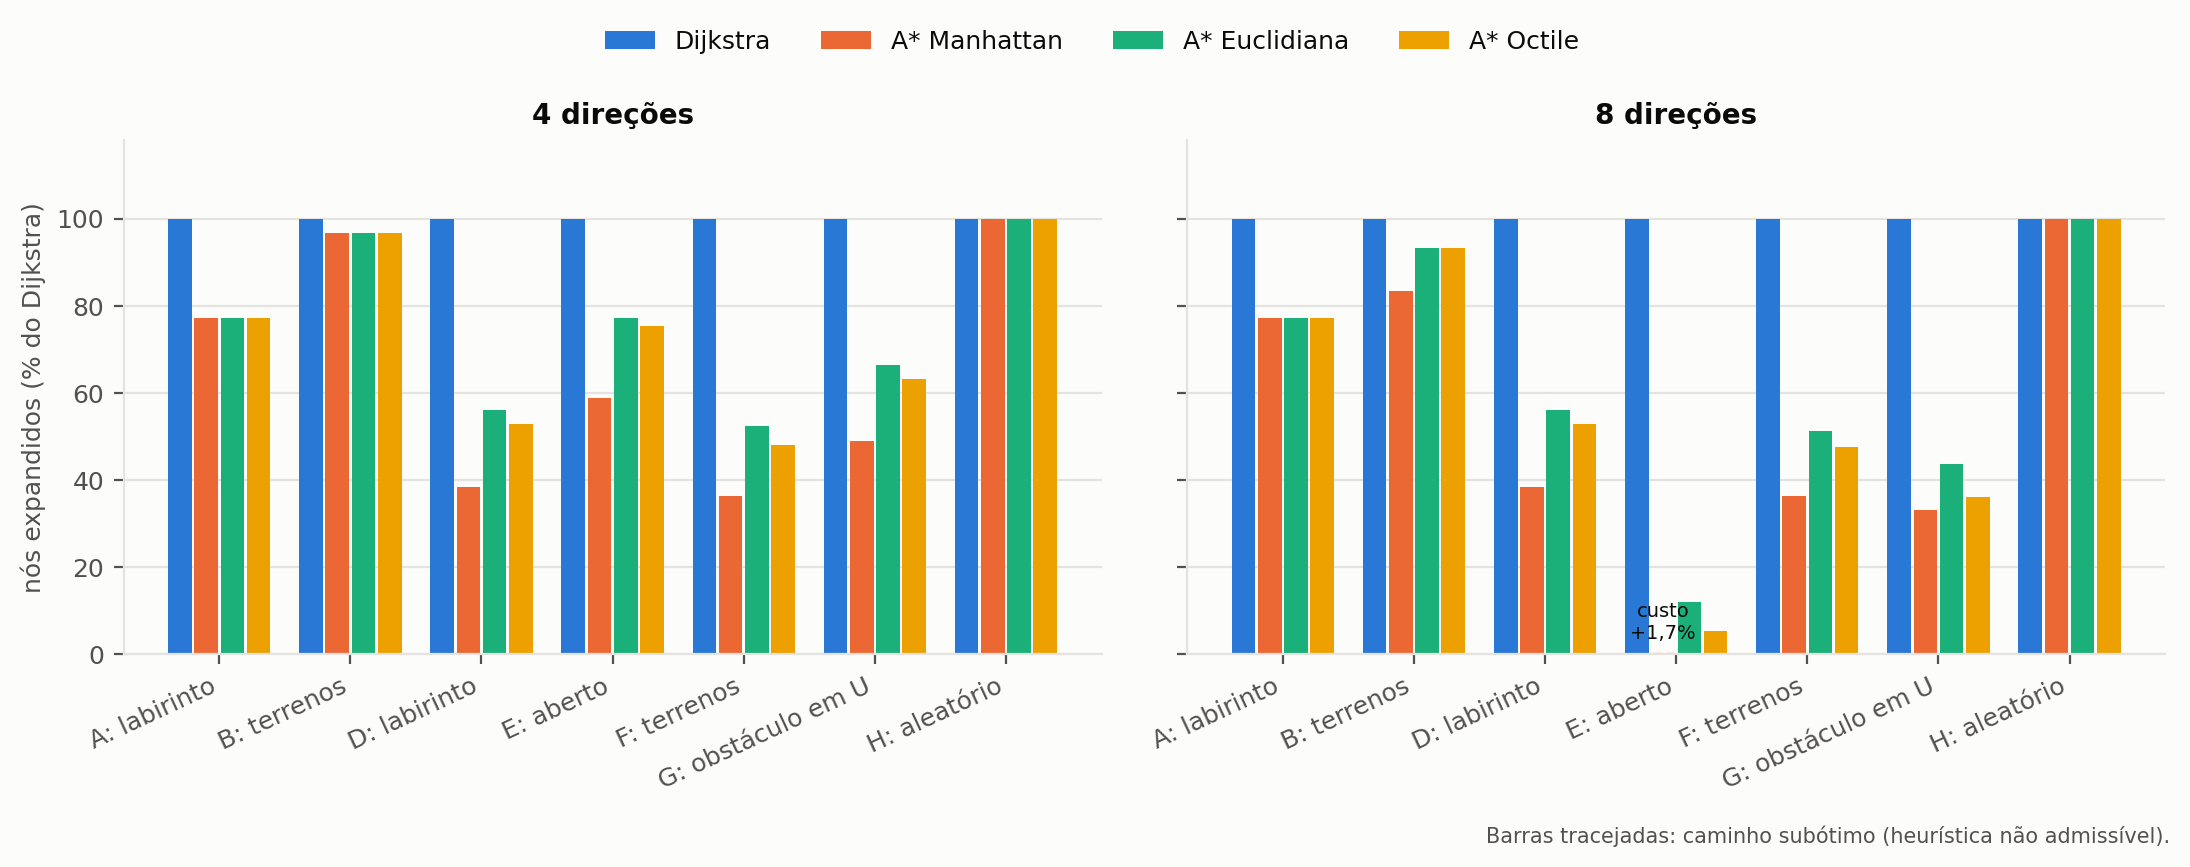

In [ ]:
display(Markdown(secao(TAB, "Heurísticas e modelos")))
ex.fig_heuristicas(plt, comp)
display(Image(ex.FIGURAS / "heuristicas_nos_expandidos.png", width=900))

## 5. Visualização dos caminhos e dos nós explorados

Em cada figura, os nós expandidos estão a azul e o caminho encontrado a laranja.
O Dijkstra está à esquerda e o A* à direita.
As figuras de todos os cenários, em 4 e 8 direções, ficam em `figuras/caminhos/`.

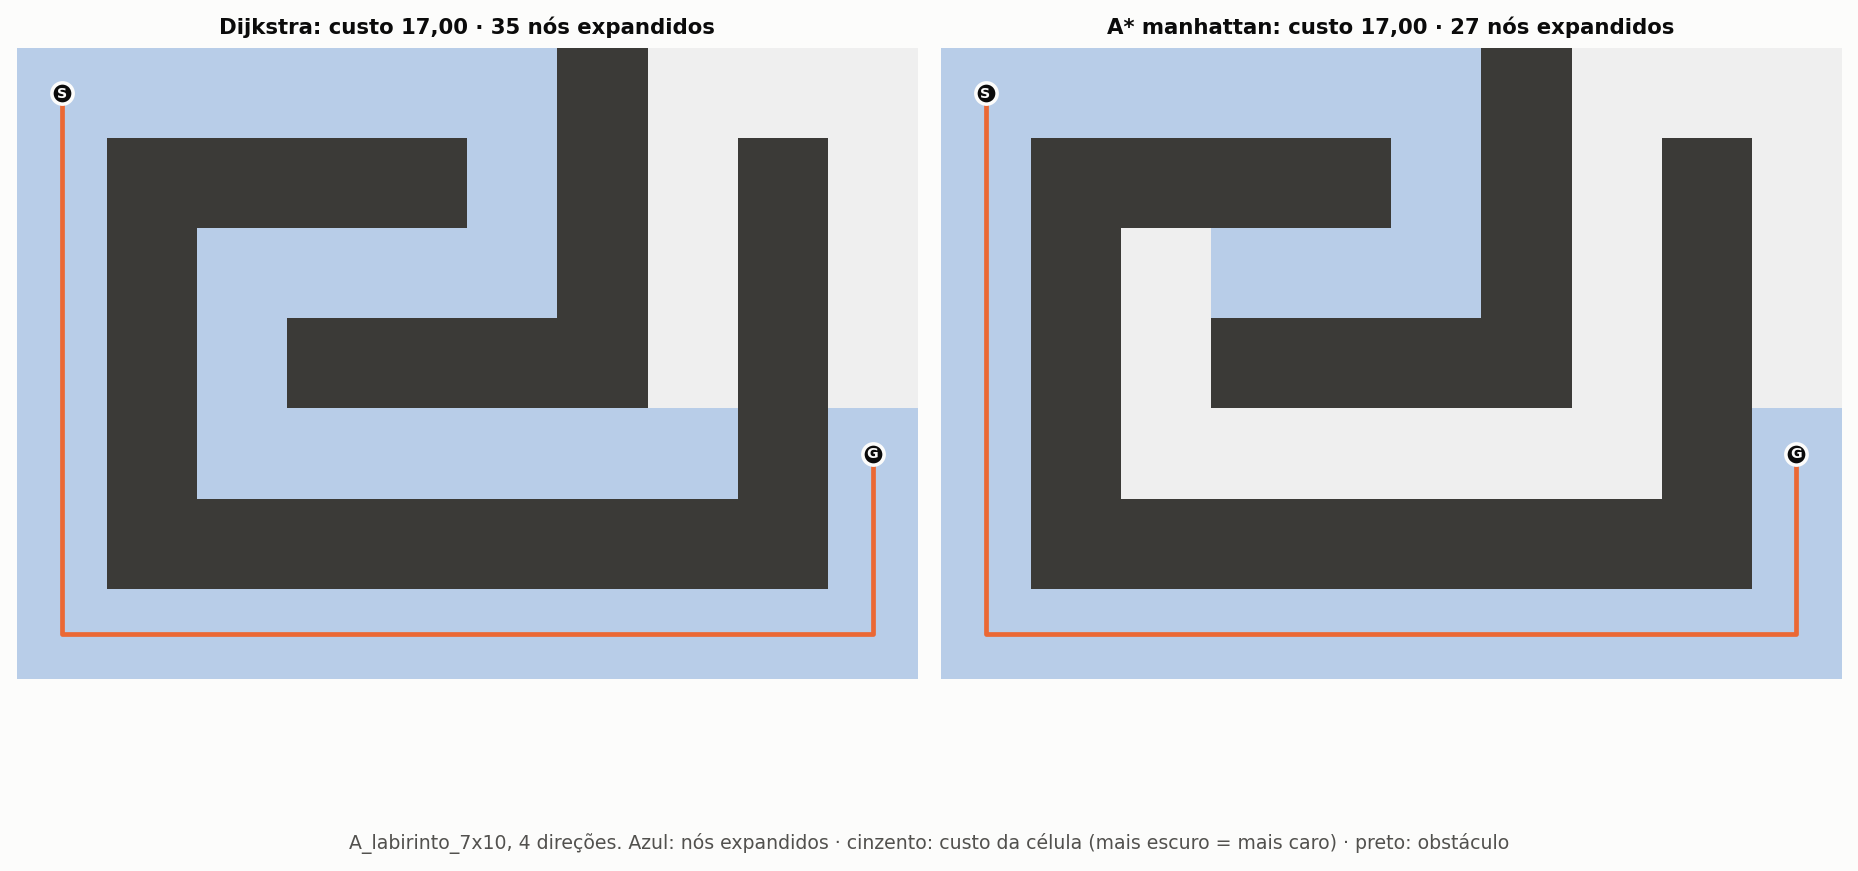

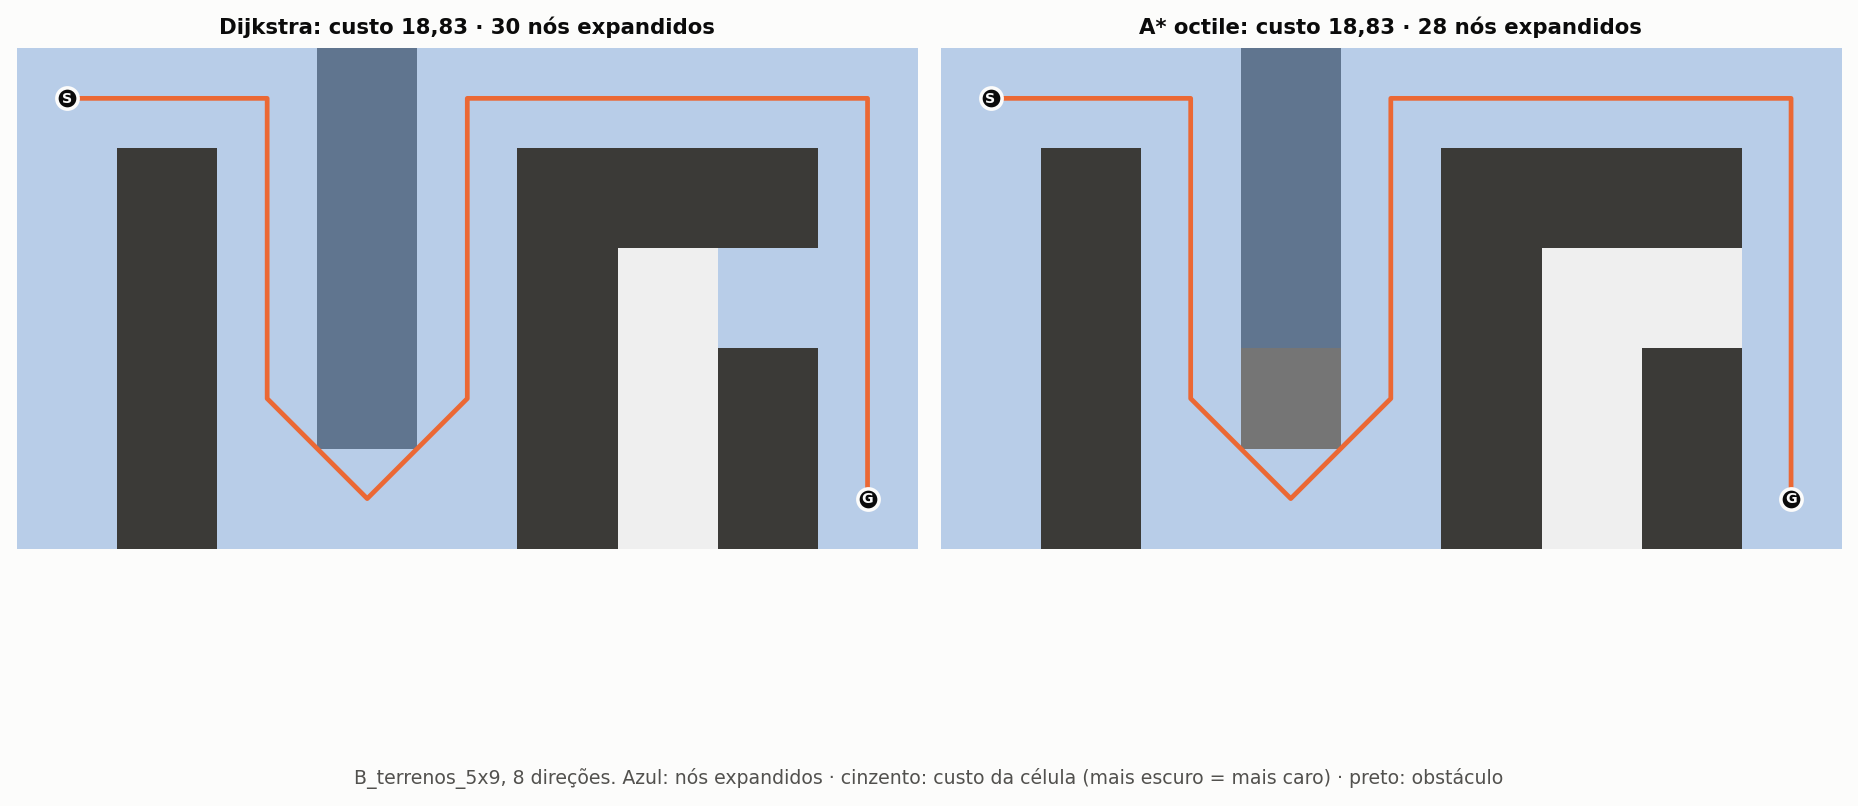

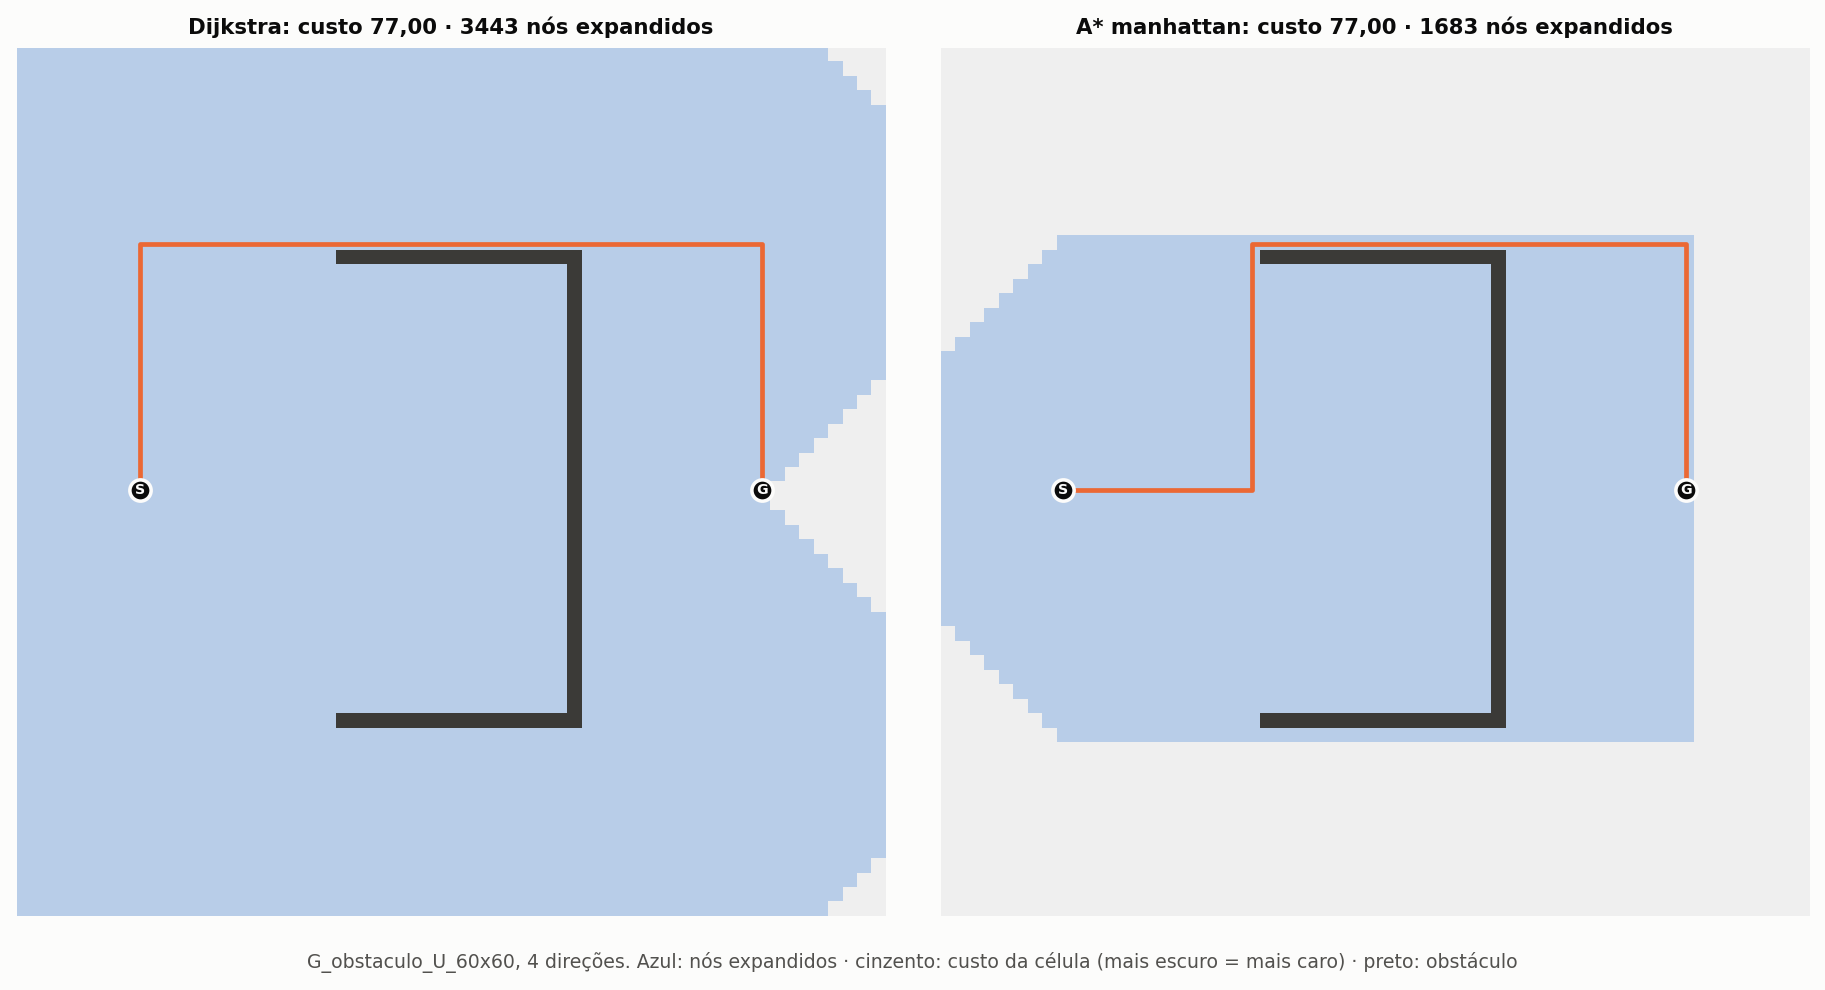

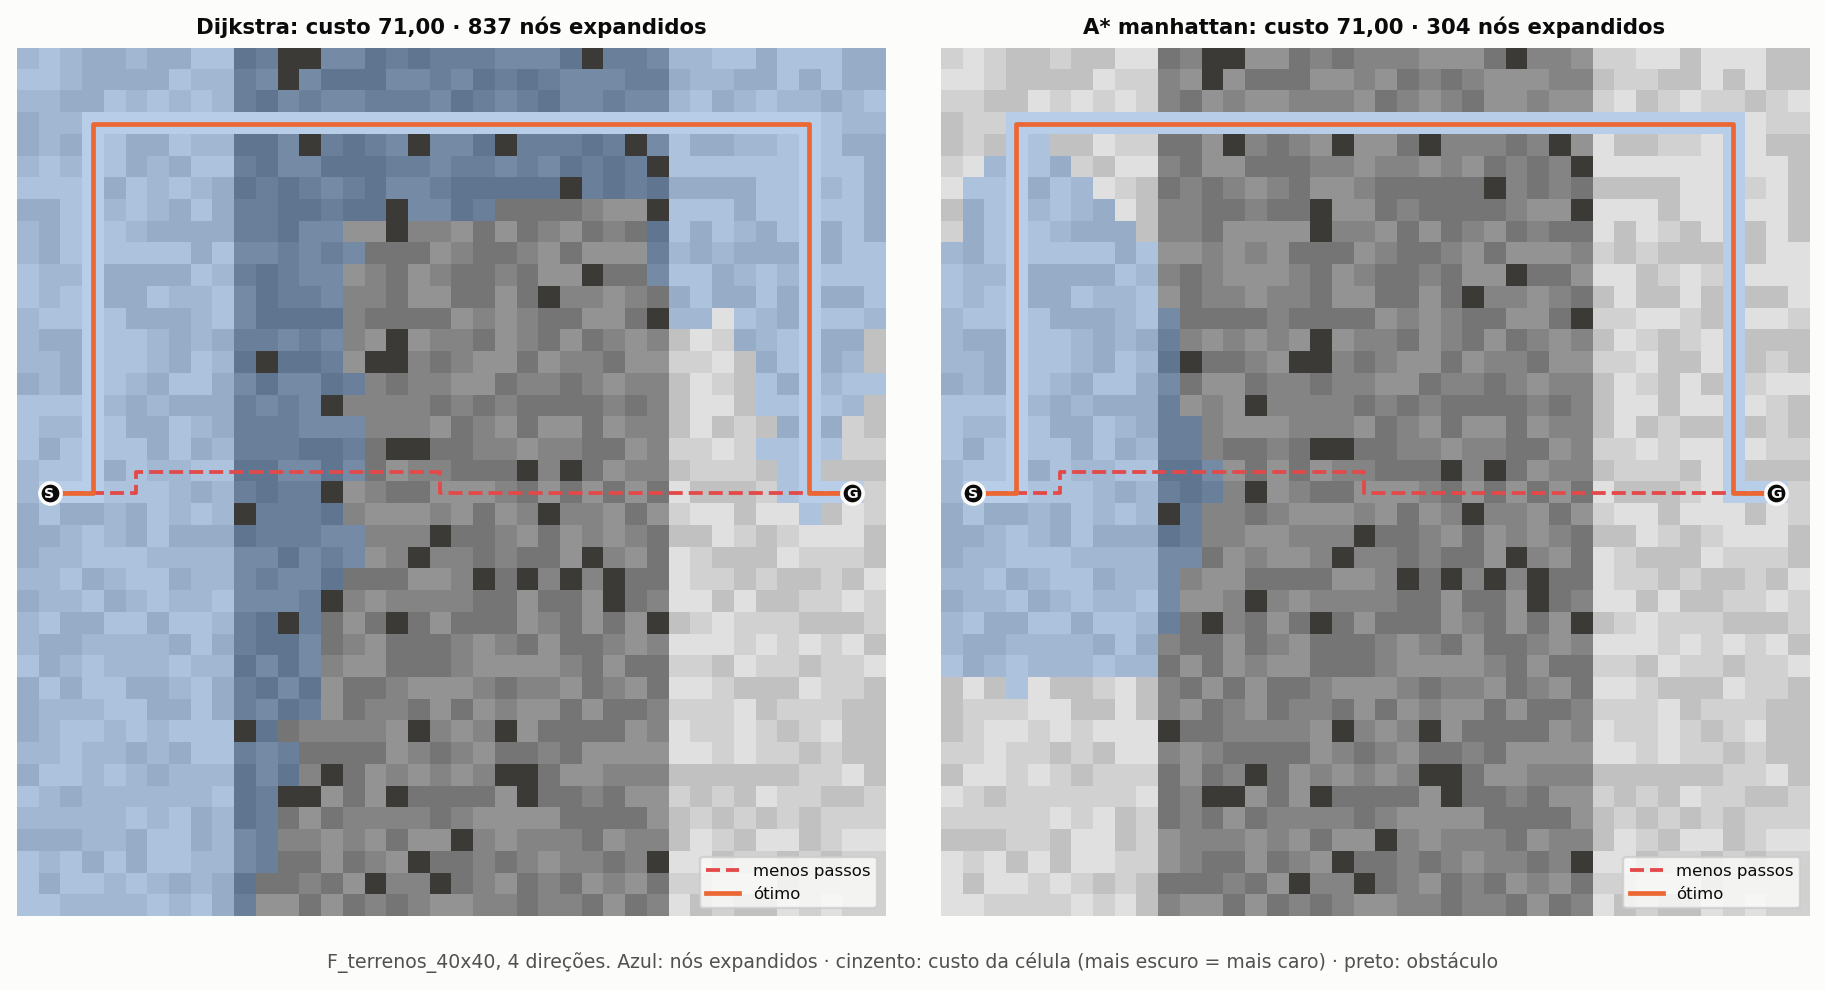

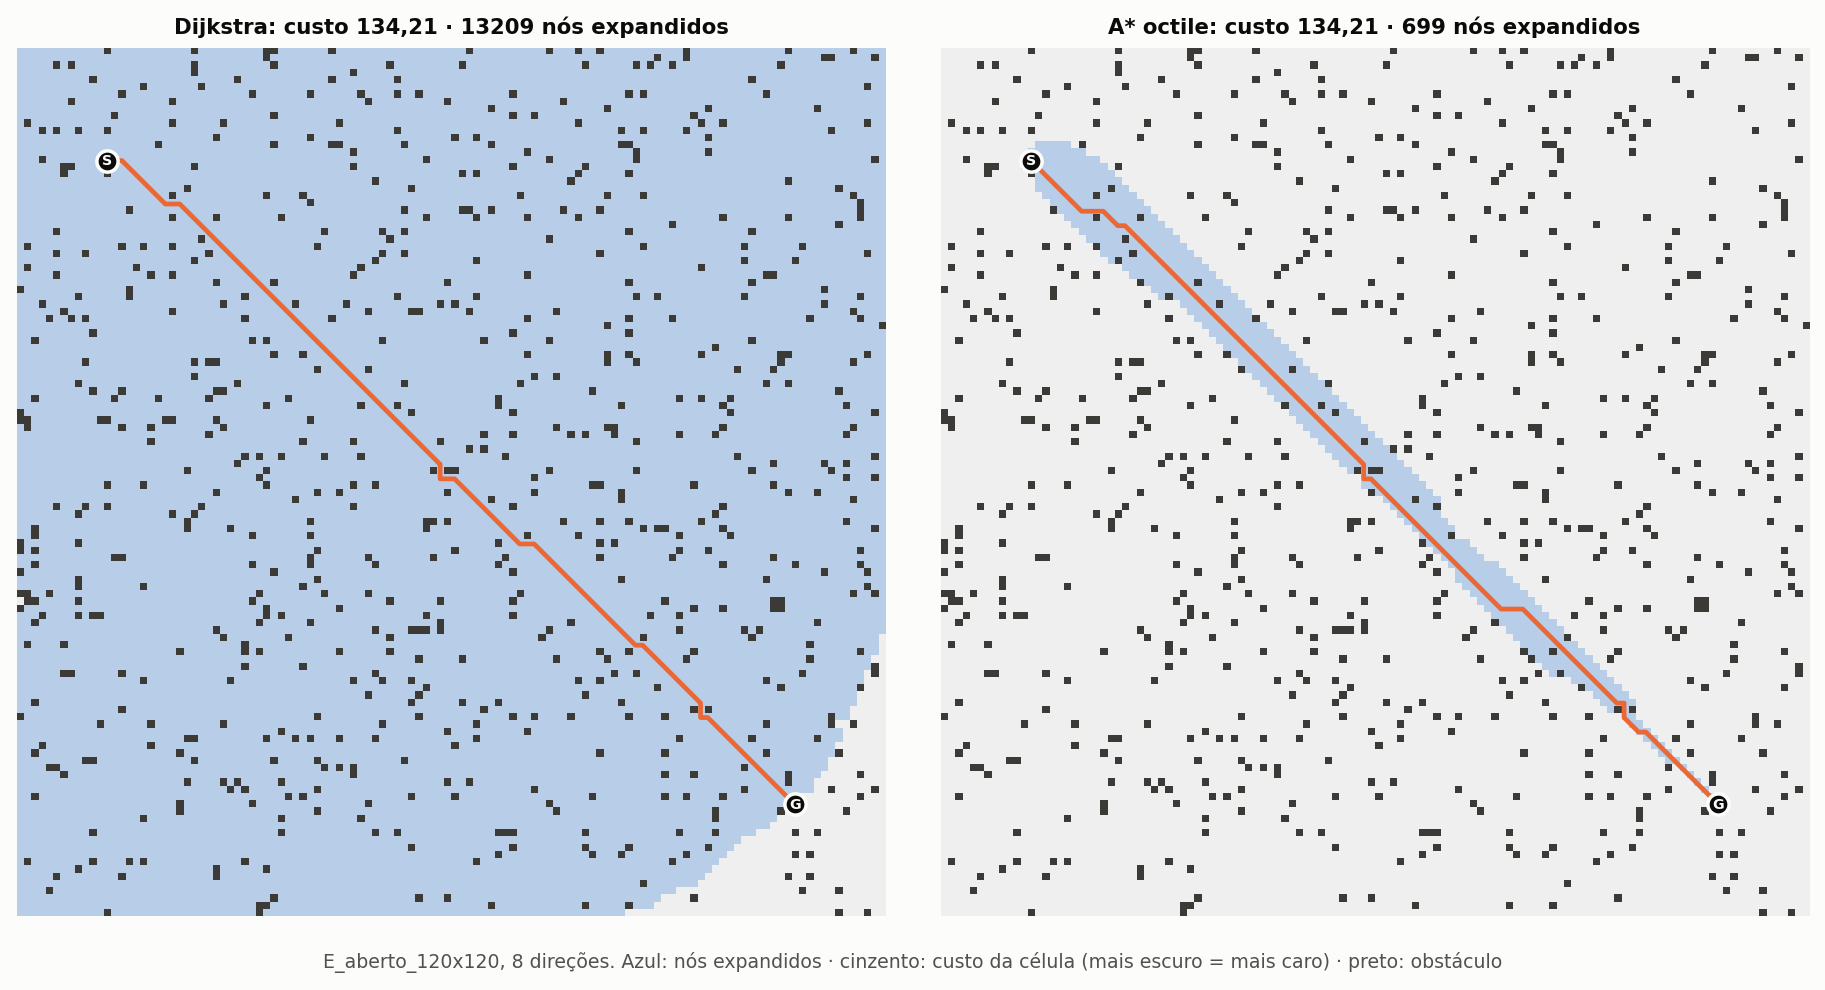

In [ ]:
for g in grelhas:
    for m in (4, 8):
        ex.fig_caminhos(plt, g, m)
for nome in ("A_labirinto_7x10_4dir", "B_terrenos_5x9_8dir", "G_obstaculo_U_60x60_4dir",
             "F_terrenos_40x40_4dir", "E_aberto_120x120_8dir"):
    display(Image(ex.FIGURAS / "caminhos" / f"{nome}.png", width=820))

## 6. Escalabilidade

Usamos mapas abertos n×n (5% de obstáculos, 4 direções), com n de 25 a 300, e a mesma semente.

### Escalabilidade (mapa aberto n×n, 5% obstáculos, 4 direções)

| n | Configuração | Custo | Nós expandidos | Memória (nós em g) | Tempo (ms) |
|---|---|---|---|---|---|
| 25 | Dijkstra | 38,00 | 570 | 574 | 0,74 |
| 25 | A* Manhattan | 38,00 | 336 | 404 | 0,52 |
| 50 | Dijkstra | 76,00 | 2304 | 2314 | 3,06 |
| 50 | A* Manhattan | 76,00 | 1379 | 1516 | 2,16 |
| 100 | Dijkstra | 154,00 | 9226 | 9245 | 12,82 |
| 100 | A* Manhattan | 154,00 | 5236 | 5519 | 8,07 |
| 150 | Dijkstra | 232,00 | 20791 | 20821 | 34,77 |
| 150 | A* Manhattan | 232,00 | 12105 | 12543 | 19,45 |
| 200 | Dijkstra | 308,00 | 36999 | 37041 | 58,33 |
| 200 | A* Manhattan | 308,00 | 21373 | 21974 | 38,14 |
| 300 | Dijkstra | 464,00 | 83343 | 83405 | 132,52 |
| 300 | A* Manhattan | 464,00 | 47188 | 48116 | 83,80 |


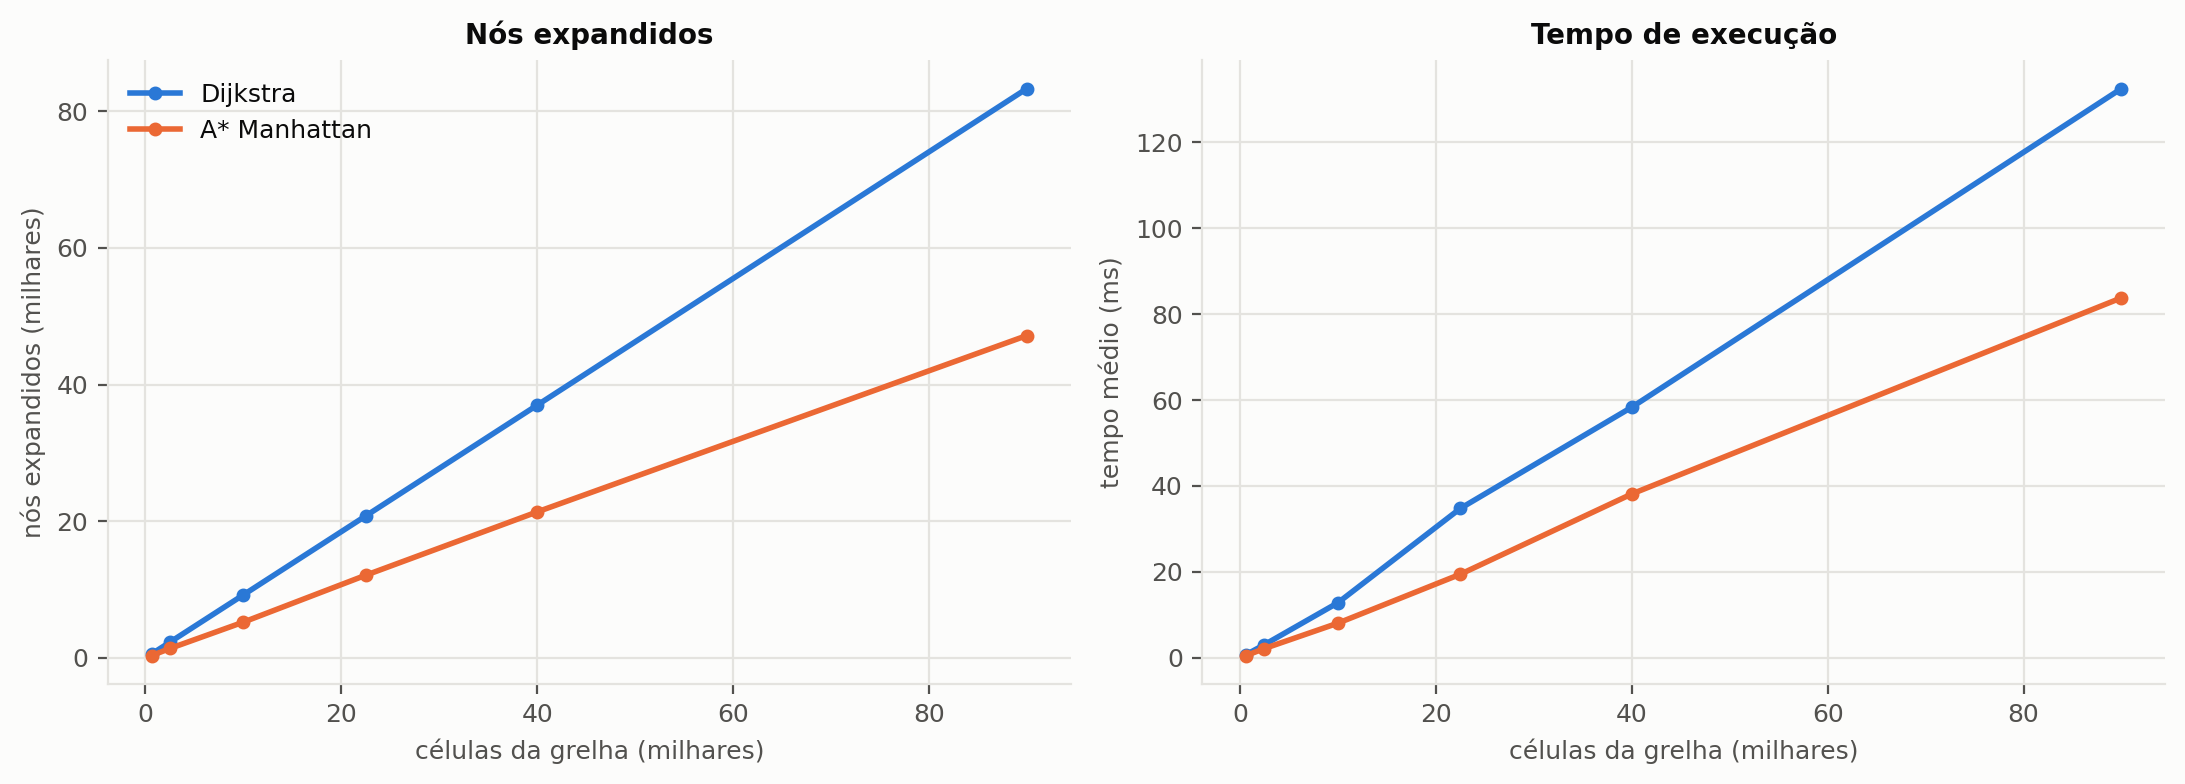

In [ ]:
display(Markdown(secao(TAB, "Escalabilidade")))
ex.fig_escalabilidade(plt, esc)
display(Image(ex.FIGURAS / "escalabilidade.png", width=900))

## 7. Extensão: Weighted A*

Usamos f(n) = g(n) + w·h(n), com a Manhattan em 4 direções e a octile em 8 direções.
O peso varia em w ∈ {1; 1,2; 1,5; 2; 3; 5}.
O limite teórico é custo ≤ w·C*, ou seja, um excesso de custo de no máximo w − 1.
Com w > 1 permitimos reabrir nós fechados quando se encontra um g menor.

### Weighted A* (excesso de custo / variação de nós face a w = 1)

| Cenário | Mov. | w=1,0 | w=1,2 | w=1,5 | w=2,0 | w=3,0 | w=5,0 |
|---|---|---|---|---|---|---|---|
| A_labirinto_7x10 | 4 | 0,0% / 0% | 0,0% / 0% | 0,0% / 0% | 0,0% / +37% | 0,0% / +41% | 58,8% / +4% |
| A_labirinto_7x10 | 8 | 0,0% / 0% | 0,0% / 0% | 0,0% / 0% | 0,0% / +4% | 0,0% / +41% | 58,8% / +4% |
| B_terrenos_5x9 | 4 | 0,0% / 0% | 0,0% / −3% | 0,0% / −3% | 0,0% / −3% | 0,0% / −3% | 0,0% / −17% |
| B_terrenos_5x9 | 8 | 0,0% / 0% | 0,0% / −4% | 0,0% / −11% | 0,0% / −11% | 0,0% / −25% | 0,0% / −25% |
| D_labirinto_61x61 | 4 | 0,0% / 0% | 0,0% / −31% | 0,0% / −34% | 13,2% / −52% | 15,8% / −68% | 15,8% / −68% |
| D_labirinto_61x61 | 8 | 0,0% / 0% | 0,0% / −15% | 0,0% / −40% | 0,0% / −72% | 0,0% / −76% | 10,5% / −77% |
| E_aberto_120x120 | 4 | 0,0% / 0% | 1,1% / −97% | 1,1% / −98% | 1,1% / −98% | 1,1% / −98% | 1,1% / −98% |
| E_aberto_120x120 | 8 | 0,0% / 0% | 0,9% / −84% | 0,9% / −85% | 1,7% / −85% | 1,7% / −85% | 1,7% / −85% |
| F_terrenos_40x40 | 4 | 0,0% / 0% | 0,0% / +6% | 0,0% / +14% | 0,0% / +32% | 1,4% / +69% | 190,1% / +41% |
| F_terrenos_40x40 | 8 | 0,0% / 0% | 0,0% / −18% | 0,0% / −26% | 2,4% / −19% | 32,0% / −13% | 45,8% / +52% |
| G_obstaculo_U_60x60 | 4 | 0,0% / 0% | 0,0% / −30% | 0,0% / −32% | 0,0% / −35% | 0,0% / −39% | 0,0% / −43% |
| G_obstaculo_U_60x60 | 8 | 0,0% / 0% | 0,0% / −19% | 0,0% / −25% | 0,0% / −30% | 0,0% / +23% | 1,9% / +83% |
| H_aleatorio_80x80 | 4 | 0,0% / 0% | 0,0% / 0% | 0,0% / 0% | 0,0% / 0% | 0,0% / −2% | 7,3% / −88% |
| H_aleatorio_80x80 | 8 | 0,0% / 0% | 0,0% / 0% | 0,0% / 0% | 0,0% / 0% | 0,0% / −5% | 3,0% / −27% |


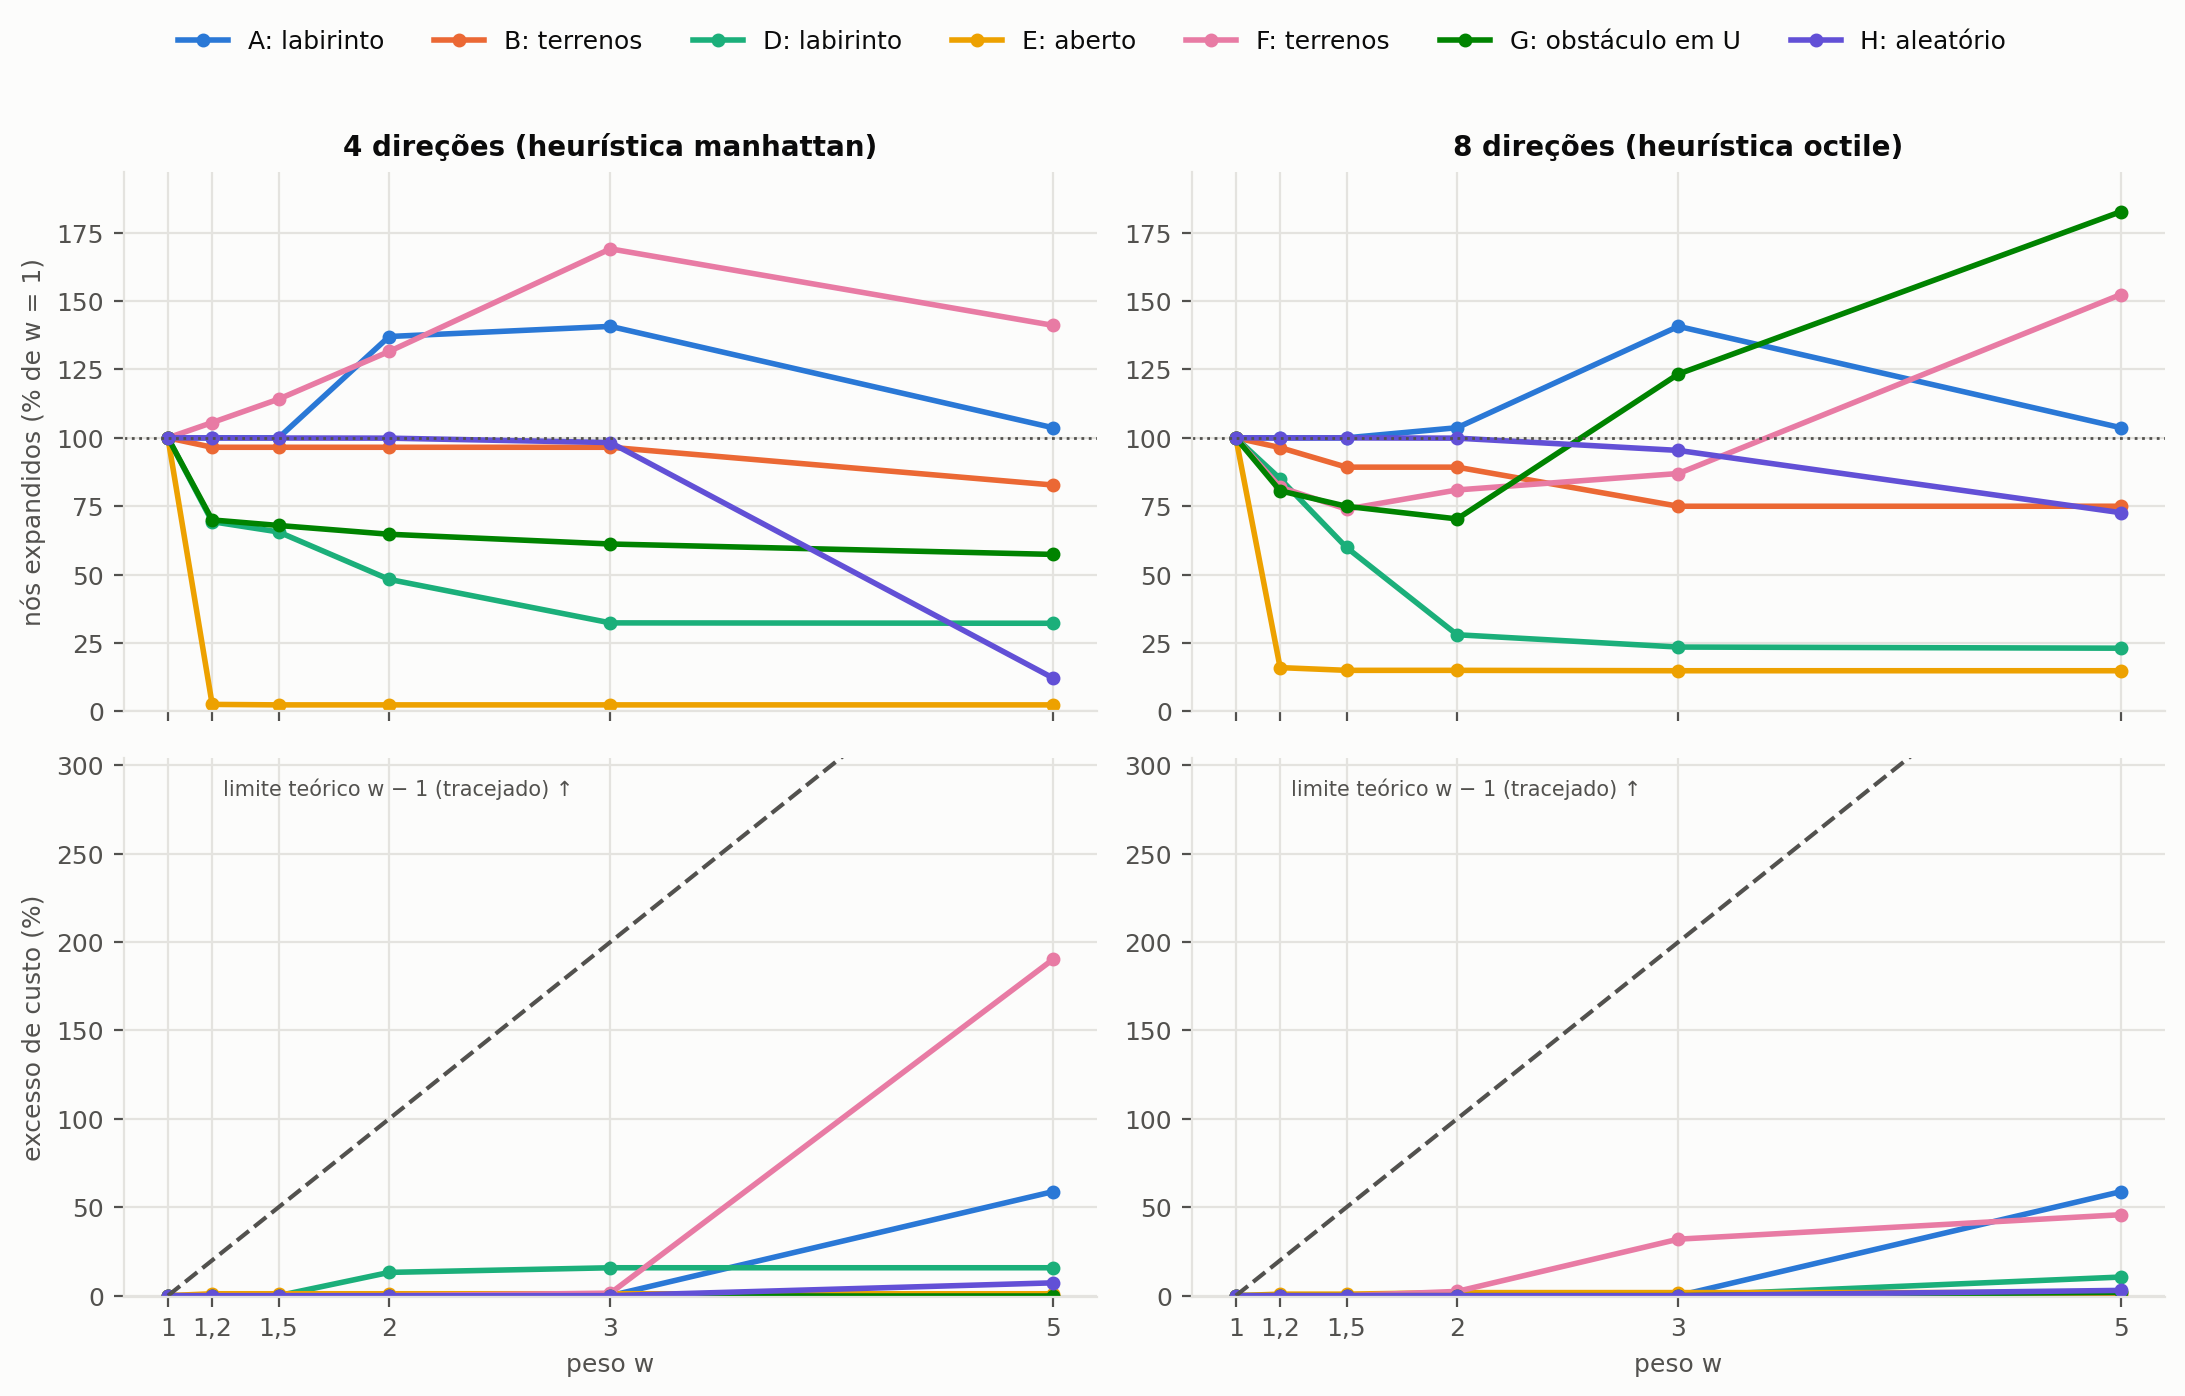

In [ ]:
display(Markdown(secao(TAB, "Weighted A*")))
ex.fig_weighted(plt, wa)
display(Image(ex.FIGURAS / "weighted_astar.png", width=900))

In [ ]:
print("Primeiro w em que o caminho deixa de ser ótimo:")
for c in dict.fromkeys(l["cenario"] for l in wa):
    for m in (4, 8):
        pts = [l for l in wa if l["cenario"] == c and l["movimento"] == m]
        p = next((p for p in pts if p["excesso"] > 1e-9), None)
        txt = (f"w = {p['w']:g}: custo +{100 * p['excesso']:.1f}%, nós {100 * p['variacao_nos']:+.0f}%"
               if p else "ótimo para todos os w")
        print(f"  {c:24s} {m} dir.: {txt}")
limite_ok = all(l["custo"] <= l["w"] * l["custo_otimo"] + 1e-9 for l in wa)
print("Limite custo ≤ w·C* respeitado em todos os casos:", limite_ok)

Primeiro w em que o caminho deixa de ser ótimo:
  A_labirinto_7x10         4 dir.: w = 5: custo +58.8%, nós +4%
  A_labirinto_7x10         8 dir.: w = 5: custo +58.8%, nós +4%
  B_terrenos_5x9           4 dir.: ótimo para todos os w
  B_terrenos_5x9           8 dir.: ótimo para todos os w
  D_labirinto_61x61        4 dir.: w = 2: custo +13.2%, nós -52%
  D_labirinto_61x61        8 dir.: w = 5: custo +10.5%, nós -77%
  E_aberto_120x120         4 dir.: w = 1.2: custo +1.1%, nós -97%
  E_aberto_120x120         8 dir.: w = 1.2: custo +0.9%, nós -84%
  F_terrenos_40x40         4 dir.: w = 3: custo +1.4%, nós +69%
  F_terrenos_40x40         8 dir.: w = 2: custo +2.4%, nós -19%
  G_obstaculo_U_60x60      4 dir.: ótimo para todos os w
  G_obstaculo_U_60x60      8 dir.: w = 5: custo +1.9%, nós +83%
  H_aleatorio_80x80        4 dir.: w = 5: custo +7.3%, nós -88%
  H_aleatorio_80x80        8 dir.: w = 5: custo +3.0%, nós -27%
Limite custo ≤ w·C* respeitado em todos os casos: True


## 8. Terrenos: caminho mais curto vs. caminho mais barato

No cenário F, o caminho com menos passos atravessa um pântano de custo 7 a 9.
O caminho ótimo contorna-o por uma estrada de custo 1.

In [ ]:
display(Markdown(secao(TAB, "Terrenos")))

### Terrenos: caminho com menos passos vs. caminho de menor custo

| Mov. | Menos passos: passos / custo | Ótimo: passos / custo |
|---|---|---|
| 4 | 39 / 206,00 | 71 / 71,00 |
| 8 | 37 / 194,97 | 67 / 68,66 |


## Conclusões

- O A* com heurística admissível devolveu sempre o custo ótimo e expandiu 41–95% menos nós do que o Dijkstra nos cenários D, E, F e G.
- O A* não trouxe ganho em dois casos. Com custos muito acima do custo mínimo assumido pela heurística (cenário H), h fica muito abaixo do custo real. Quando não há caminho (cenários C e I), é preciso explorar toda a região de S. Nesses casos o A* é até um pouco mais lento, por calcular h.
- A Manhattan em 8 direções não é admissível e perdeu a otimalidade no cenário E. Em 8 direções, a octile é a melhor heurística admissível.
- O Weighted A* compensa muito em espaços abertos: no cenário E, com w = 1,2, expande 97% menos nós e o caminho fica 1,1% mais caro. Nos terrenos de custo muito variável pode expandir mais nós do que o A*. O excesso de custo ficou sempre muito abaixo de w − 1.